In [63]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append('..')

import json
import numpy as np

import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable

from tqdm import tqdm

mpl.rc('text', usetex=True)
mpl.rcParams['text.latex.preamble'] = r"\usepackage{amsmath} \usepackage{xfrac}"

tex_fonts = {"font.family": "serif",
             "font.size": 11,
             "axes.labelsize": 11,
             "legend.fontsize": 11,
             "xtick.labelsize": 8,
             "ytick.labelsize": 8}

plt.rcParams.update(tex_fonts)

marker_options = {'marker': 'o',
                  'markeredgecolor': 'black',
                  'markeredgewidth': 1.0,
                  'markersize': 5}

cmap = sns.color_palette('deep', as_cmap=True)

def set_size(width="revtex4.2", fraction=1, subplots=(1, 1), golden_ratio = 0.6180339887498949):
    """Set figure dimensions to avoid scaling in LaTeX.

    Parameters
    ----------
    width: float or string
            Document width in points, or string of predined document type
    fraction: float, optional
            Fraction of the width which you wish the figure to occupy
    subplots: array-like, optional
            The number of rows and columns of subplots.
    Returns
    -------
    fig_dim: tuple
            Dimensions of figure in inches
    """
    if width == 'revtex4.2':
        width_pt = 510.0
    else:
        width_pt = width

    # Width of figure (in pts)
    fig_width_pt = width_pt * fraction
    # Convert from pt to inches
    inches_per_pt = 1 / 72.27

    # Figure width in inches
    fig_width_in = fig_width_pt * inches_per_pt
    # Figure height in inches
    fig_height_in = fig_width_in * golden_ratio * (subplots[0] / subplots[1])

    return (fig_width_in, fig_height_in)

def load_training_results(file_name: str, data_folder = "../data/optimisation_data/"):
    """
    Save results of the function 'optimize_tn' in json format. 
    Complex values are transformed into strings for json serialisation.
    """
    with open(data_folder + file_name, 'r') as file:
        res = json.load(file)

        # Params during training
        res['params'] = [{int(k): np.array(v, dtype=complex) for k, v in p.items()} for p in res['params']]

        # Params of the MPOs, self-explanatory
        mpo_params_keys = [] #['params_true_mpo', 'params_inv_opt_mpo', 'params_inv_true_mpo']
        for key in mpo_params_keys:
            res[key] = {int(k): np.real_if_close(np.array(v, dtype=complex)) for k, v in res[key].items()}
        
        ignore_keys = ['probs', 'data_file', 'params', 'noise_type', 'lr', 'params_true_mpo', 'params_inv_opt_mpo', 'params_inv_true_mpo'] + mpo_params_keys
        for k in set(res.keys()).difference(ignore_keys):
            res[k] = np.real_if_close(np.array(res[k], dtype=complex))
        
    return res

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [71]:
no_spam_fname = 'cxeven_nq10_gen_dict_bigger_231127_kyiv_50q_ns1000000_global_repeated_sic_states_2023-11-29_seed46.json'

no_qdt_fnames = {'1e-4': 'spam/cxeven_nq10_gen_dict_bigger_231127_kyiv_50q_ns1000000_global_repeated_meas0.0001_2024-07-15_seed34343400.json',
                 '1e-3': 'spam/cxeven_nq10_gen_dict_bigger_231127_kyiv_50q_ns1000000_global_repeated_meas0.001_2024-07-15_seed34343400.json',
                 '1e-2': 'spam/cxeven_nq10_gen_dict_bigger_231127_kyiv_50q_ns1000000_global_repeated_meas0.01_2024-07-15_seed34343400.json',
                 '1e-1': 'spam/cxeven_nq10_gen_dict_bigger_231127_kyiv_50q_ns1000000_global_repeated_meas0.1_2024-07-15_seed34343400.json'}

w_qdt_fnames  = {'1e-4': 'spam/qdt_cxeven_nq10_gen_dict_bigger_231127_kyiv_50q_ns1000000_global_repeated_meas0.0001_2024-07-15_seed12.json',
                 '1e-3': 'spam/qdt_cxeven_nq10_gen_dict_bigger_231127_kyiv_50q_ns1000000_global_repeated_meas0.001_2024-07-15_seed13.json',
                 '1e-2': 'spam/qdt_cxeven_nq10_gen_dict_bigger_231127_kyiv_50q_ns1000000_global_repeated_meas0.01_2024-07-15_seed11.json',
                 '1e-1': 'spam/qdt_cxeven_nq10_gen_dict_bigger_231127_kyiv_50q_ns1000000_global_repeated_meas0.1_2024-07-15_seed10.json'}

In [72]:
key = 'frob_distance'

d = load_training_results(no_spam_fname)
best_idx = np.argmin(d['test_loss'])
no_spam = np.min(d[key]).round(8)

for k, v in no_qdt_fnames.items():
    no_qdt = {k: np.min(load_training_results(v)[key]).round(8) for k, v in no_qdt_fnames.items()}

w_qdt  = {k: np.min(load_training_results(v)[key]).round(8) for k, v in w_qdt_fnames.items()}

print(no_spam)
print(no_qdt)
print(w_qdt)

0.00015288
{'1e-4': 0.00015087, '1e-3': 0.00029045, '1e-2': 0.00496719, '1e-1': 0.23134499}
{'1e-4': 0.00021694, '1e-3': 0.00020152, '1e-2': 0.00028821, '1e-1': 0.00058335}


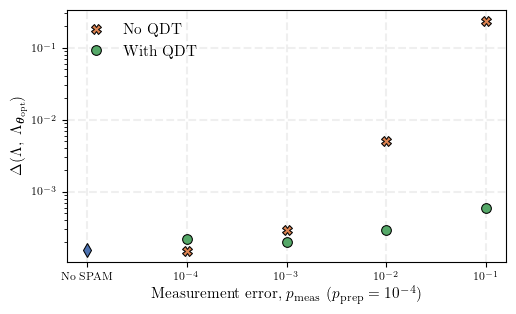

In [76]:
markersize = 7
capsize = 5

markers = ['o', 'X', 'd']
labels = ["With QDT", "Without QDT"]

shots = range(5)

fig = plt.figure(figsize=set_size(fraction=0.75))

plt.plot(0, no_spam, color = cmap[0], marker = 'd', ms = markersize, markeredgecolor='black', mew=0.75)

for i, v in enumerate(no_qdt.values()):
    plt.plot(i+1, v,  color = cmap[1], marker = 'X', ms = markersize, markeredgecolor='black', mew=0.75)

plt.plot([],[], lw = 0, color = cmap[1], marker = 'X', ms = markersize, markeredgecolor='black', mew=0.75, label = "No QDT")

for i, v in enumerate(w_qdt.values()):
    plt.plot(i+1, v,  color = cmap[2], marker = 'o', ms = markersize, markeredgecolor='black', mew=0.75)
plt.plot([],[], lw = 0, color = cmap[2], marker = 'o', ms = markersize, markeredgecolor='black', mew=0.75, label = "With QDT")

plt.yscale('log')
plt.xlabel(r"Measurement error, $p_\text{meas}$   $(p_{\text{prep}} = 10^{-4})$")
plt.ylabel(r"$\Delta(\Lambda,~\Lambda_{\boldsymbol{\theta_\textrm{opt}}})$")

plt.xticks(range(5), ['No SPAM', '$10^{-4}$', '$10^{-3}$', '$10^{-2}$', '$10^{-1}$'])

plt.legend(frameon=False)

plt.grid(ls = "--", lw = 1.5, alpha = 0.2)

plt.tight_layout()
plt.savefig('accuracy_vs_spam.pdf', format="pdf")